Universidad Torcuato Di Tella

*Licenciatura en Tecnología Digital*

**Métodos Computacionales — Reconstrucción y regularización en imágenes tomográficas**
# **Trabajo Práctico — Ejercicio N°4: ¿Es posible reconstruir la imagen de manera única?**

Antes de comenzar a resolver, importamos los módulos que utilizaremos en el desarrollo.

In [2]:
# Importamos los módulos
import numpy as np
import matplotlib.pyplot as plt

Además, corremos los bloques necesarios de ejercicios anteriores para poder realizar este ejercicio:

In [3]:
# Ejercicio 3

# Definimos `X_fantoma`
X_fantoma:np.ndarray = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Aplanamos la matriz `X_fantoma` para dar lugar a `x_fantoma`
x_fantoma = X_fantoma.reshape(-1)

In [4]:
# Ejercicio 3
def mascara_rayo(n:int, direccion:tuple[int,int], s:int):
    r'''
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direccion` -> dirección del rayo (fija una familia de rayos paralelos).
    - `s` -> distancia del rayo al origen (fija un rayo).

    Devuelve:
    - La matriz que representa la mascara del rayo sobre la imagen.
    '''
    res:np.ndarray = np.zeros(shape=(n,n), dtype=np.int8)
    for i in range(0,len(res)):
        for j in range(0,len(res)):
            if (direccion[0] * i) + (direccion[1] * j) == s:
                res[i][j] = 1
    return res

In [5]:
# Ejercicio 3
def matriz_proyeccion(n:int, direcciones:list[tuple[int, int]]):
    r'''
    
    Recibe:
    - `n` -> dimensión de la matriz (se asume cuadrada).
    - `direcciones` -> vector de direcciones a utilizar.

    Devuelve:
    - La matriz compuesta por las máscaras de todos los rayos correspondientes.
    - La lista de todos los rayos generados, con el ángulo y el s correspondiente.
    '''
    A:list[list[int]] = list()
    res:list[tuple[tuple[int,int], int]] = list()
    for dir in direcciones:
        rayos:set[int] = set()
        for i in range(n):
            for j in range(n):
                s = dir[0] * i + dir[1] * j
                rayos.add(s)
        rayos_lista:list[int] = list(rayos)
        rayos_lista.sort()
        rayos_array:np.ndarray = np.array(rayos_lista)

        for rayo in rayos_array:
            fila_A = mascara_rayo(n, dir, rayo)
            fila_A = fila_A.reshape(-1)
            A.append(fila_A) # type: ignore
            res.append((dir, rayo))

    return A, res

Continuaremos trabajando con la matriz $X_{fantoma}$ y el vector $x_{fantoma}$ del Ejercicio 1, junto con la función `matriz_proyeccion` implementada anteriormente. El objetivo es investigar si las mediciones $b = Ax$ contienen información suficiente para recuperar una imagen de $8\times8$ de manera única. Para ello, analizaremos el rango y el espacio nulo de distintas matrices de proyección.

1. Considerar una matriz de proyección $A \in \mathbb{R}^{m \times 64}$. Utilizando el teorema de rango y nulidad, determinar qué condición debe cumplir $rango(A)$ para que la imagen pueda reconstruirse de manera única. Explicar qué ocurre si existe un vector no nulo $v$ tal que $Av = 0$ y relacionar $rango(A)$ con $dim(Nul(A))$.

Sea $x_{fantoma}$ la imagen a reconstruir aplanada. Reconstruir la imagen de manera única y unívoca es equivalente a garantizar que el sistema $Ax_{fantoma} = b$ es consistente determinado, es decir, que posee solución única $\forall \ b \in \mathbb{R}^m$. Además, por teorema de la matriz invertible, esto es equivalente a pedir que $A$ sea invertible. Para que esto ocurra, $m$ debe ser igual a $64$ para garantizar que $A$ sea cuadrada, requisito indispensable para asegurar la invertibilidad.

A su vez, por el mismo teorema, esto necesariamente implica que $rango(A) = n = 64$, y por el teorema de rango y nulidad, también implica que $dim(Nul(A)) = 0$. Esta condición se rompe si existe un $v \ne 0$ tal que $Av=0$, en cuyo caso la imagen no se puede reconstruir de manera única.

2. Construir las matrices $A_2$, $A_4$ y $A_7$ utilizando $D_2 = \{(1,0),(0,1)\}$,  $D_4 = D_2 \cup \{(1,1),(1,−1)\}$ y  $D_7 = D_4 \cup \{(2,1),(1,2),(3,1)\}$. Para cada matriz, informar sus dimensiones, su rango, la dimensión de su espacio nulo y si permite determinar una imagen de manera única. Comparar la cantidad de filas con el rango e identificar la presencia de mediciones redundantes.

In [6]:
import numpy as np

# Para definir dimensiones de la matriz (nxn)
n = 8

D2 = [(1,0),(0,1)]
D4 = [(1,0),(0,1),(1,1),(1,-1)]
D7 = [(1,0),(0,1),(1,1),(1,-1),(2,1),(1,2),(3,1)]

# Construímos A2, A4, A7
A2 = matriz_proyeccion(n, D2)[0]
A4 = matriz_proyeccion(n, D4)[0]
A7 = matriz_proyeccion(n, D7)[0]

# Imprimimos dimensiones y rangos de las matrices construidas
print("Dimensiones de A2: ", np.shape(A2))
print("Dimensiones de A4: ", np.shape(A4))
print("Dimensiones de A7: ", np.shape(A7), "\n")

print("Rango de A2: ", np.linalg.matrix_rank(A2))
print("Rango de A4: ", np.linalg.matrix_rank(A4))
print("Rango de A7: ", np.linalg.matrix_rank(A7), "\n")

print("dim(Nul A2): ", 64 - np.linalg.matrix_rank(A2))
print("dim(Nul A4): ", 64 - np.linalg.matrix_rank(A4))
print("dim(Nul A7): ", 64 - np.linalg.matrix_rank(A7), "\n")

Dimensiones de A2:  (16, 64)
Dimensiones de A4:  (46, 64)
Dimensiones de A7:  (119, 64) 

Rango de A2:  15
Rango de A4:  39
Rango de A7:  64 

dim(Nul A2):  49
dim(Nul A4):  25
dim(Nul A7):  0 



Dado que, por el momento, ninguna de las matrices obtenidas es cuadrada, no se puede reconstruir la imagen de manera única. Sin embargo, en el caso de $A_7$, se puede observar que $rango(A_7)=64$ y $dim(Nul\ A_7)=0$. Esto implica que contamos con mediciones (filas) redundantes, visto que hay más filas que columnas. Ello no quita que se pueda realizar un análisis de dependencia entre filas para prescindir de aquellas que no aportan información nueva. De esta manera, se puede llegar a una $A_7'$ cuadrada tal que se respete la condición de reconstrucción única.

3. Para $A_4$, utilizar una descomposición SVD para encontrar un vector no nulo $v \in R^{64}$ que pertenezca aproximadamente a su espacio nulo y verificar que $∥A_4v∥\approx0$. Calcular $b_4 = A_4x_{fantoma}$ y construir $x_{alt} = x_{fantoma} + \gamma v$, con $\gamma \ne 0$. Visualizar y verificar que producen aproximadamente
las mismas mediciones e interpretar qué información de la imagen resulta invisible para $A_4$.

A continuación, implementamos la descomposición SVD para $A_4$.

In [7]:
# Descomposición en valores singulares de A4
U, valores_singulares, Vt = np.linalg.svd(A4)

# Tomamos al valor singular más chico de A4
valores_singulares.sort(descending=False)
sigma_cero = valores_singulares[0]

# Lo imprimimos
print(sigma_cero) # Pŕacticamente cero

3.92610780688193e-16


Notamos que el valor singular más chico de $A_4$, es decir, $\sigma_0$ corresponde a un valor prácticamente nulo. Luego, el vector singular asociado a $\sigma_0$ es la última fila de $V^T$ a la que llamaremos $v$. En particular, este vector singular verifica que:

$$
∥A_4v∥ = ∥\sigma_0v∥ = |\sigma_0|∥v∥ \approx 0 ∥v∥ \approx 0
$$

In [8]:
# Verificamos el cálculo hecho previamente
norma = np.linalg.norm(A4 @ Vt[-1])
round(float(norma), 2)

0.0

In [9]:
# Calculamos las mediciones b4_fantoma = A4*x_fantoma
b4_fantoma = A4 @ x_fantoma


for g in [1, 10, 100, 1000]:
    # Construímos x_alt bajo gamma=1000
    gamma = g
    x_alt = x_fantoma + gamma * Vt[-1]

    # Calculamos las mediciones b4_alt = A4 * x_alt
    b4_alt = A4 @ x_alt
    print(f"Mediciones b4_alt bajo gamma = {gamma}: {b4_alt}")

Mediciones b4_alt bajo gamma = 1: [ 2.77555756e-17  1.70000000e+00  3.30000000e+00  2.30000000e+00
  2.00000000e+00  2.40000000e+00  1.40000000e+00  3.05311332e-16
 -6.93889390e-17  1.70000000e+00  3.30000000e+00  2.30000000e+00
  2.00000000e+00  2.40000000e+00  1.40000000e+00  1.94289029e-16
 -1.84165870e-16 -2.84494650e-16  8.32667268e-17  1.60000000e+00
  1.40000000e+00  2.20000000e+00  1.50000000e+00  1.20000000e+00
  1.50000000e+00  1.60000000e+00  1.10000000e+00  1.00000000e+00
  1.24900090e-16  3.46944695e-17  1.11022302e-16  1.59594560e-16
  5.55111512e-17  0.00000000e+00  6.00000000e-01  9.00000000e-01
  1.20000000e+00  2.90000000e+00  1.90000000e+00  2.90000000e+00
  1.20000000e+00  9.00000000e-01  6.00000000e-01  2.77555756e-17
  2.77555756e-17 -4.16333634e-17]
Mediciones b4_alt bajo gamma = 10: [ 4.44089210e-16  1.70000000e+00  3.30000000e+00  2.30000000e+00
  2.00000000e+00  2.40000000e+00  1.40000000e+00  3.10862447e-15
 -5.82867088e-16  1.70000000e+00  3.30000000e+00  2.

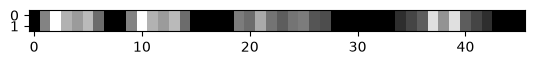

In [10]:
# Comparamos visualmente b4_fantoma contra b4_alt (bajo gamma=1000)
plt.imshow([b4_fantoma, b4_alt], cmap='gray')

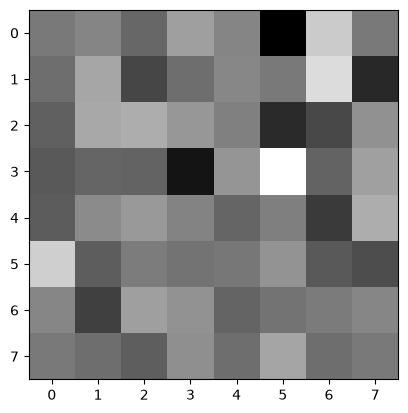

In [11]:
# Tomamos el v escalado en gamma y lo visualizamos 
# como una imagen tal como haríamos con x_fantoma

# Lo convertimos en una matriz cuadrada de 8x8
vs_reshaped = (gamma * Vt[-1]).reshape(8, 8)

# Visualizamos la imagen
plt.imshow(vs_reshaped, cmap='gray')

Podemos concluir que $v$ como imagen aplanada (donde cada píxel contiene el nivel de atenuación correspondiente) representa un patrón de información que la matriz de proyección $A_4$ no es capaz de captar para trasladar a las mediciones. De esta manera, para cualquier imagen $x_{alt}$ que se pueda expresar de manera tal que $x_{alt} = x + \gamma v$, las mediciones obtenidas al aplicar $A_4$ pasarán por alto este tipo de patrón en la atenuación de la imagen.